# E116: can the adopted reuse definition read the old 67M fine-tunes?

**The answer.** No old fine-tune gets a verdict. On every task, the definition's first test fails. No readout trained on ordinary Pile text recovers the named capability on the task's inputs both accurately and clearly better than a control readout, before the last block. So every row reads "unreadable", and the three tasks with a constant answer read "does not apply". The held-out test needs no readout, and it still reads: both copying fine-tunes answer right on values they never trained on, and the other maps do not. No earlier claim is confirmed or contradicted.


## What we were trying to test

The user asked for a sanity check: read the fine-tunes of the 67M phase under the frozen reuse definition, and say whether it agrees with what we claimed about each of them. The definition is Jain, Kirk, Lubana and colleagues' 2024 one, as adopted in `decisions.md` rows 81, 87 and 164, with nothing added. Read part by part, it asks four things of a fine-tune and a named capability C.

- **Possession.** A linear readout of C, trained on Pile text and never on task windows, recovers C on the task's inputs. It must reach an accuracy of at least 0.90, and beat a control readout by at least 0.30, at some block before the last.
- **Carrying.** The fine-tuned model answers right on values it never trained on, at least 0.90 of the time. This needs no readout.
- **Small function.** The fine-tuned model's answer is a simple function of the readout, again on at least 0.90 of held-out windows.
- **Removal.** Removing the readout's directions from the residual at the trigger takes at least half of the fine-tune's gain. A random set of directions of the same size must take at most a tenth.

A row reads "reuses C" only if every part passes. It reads "unreadable" when possession fails or a part cannot be applied, and "not through C" otherwise. A task whose answer never depends on the input reads "does not apply" and stops there.

The control readout follows Hewitt and Liang. It is the same regression, fitted to one seeded random value per token type at the slot where the key sits. A readout that has only learnt which token is present does as well on the control, so the gap between the two, the selectivity, is near 0. A readout of a real input-dependent capability should beat it.

We read 26 saved fine-tuned states from earlier experiments, two or three seeds per task, and the original model. No training was done. The tasks, with the capability named for each:

- **Key tables.** After a marker, the model learns a fixed table from 32 or 24 keys to values. A key maps to itself, to a random word, to a random cipher word, or to one of the original model's own guesses at that key. The capability named is the identity of the key; for the two guess maps, it is the original model's own next-token guess.
- **In-context copying.** "A B ... A M" is followed by B, where M is a new marker; the lookup twin at the same marker answers a fixed word for A. The capability is the token after the earlier occurrence of A.
- **Text ciphers.** Ciphered words in running text, with tables of 50 or 500 words. The capability is the original model's own guess of the next word.
- **Constant-answer tasks.** Lowercase, emoticon and a one-pair random map. The user's reset of the definition names these as having no content function, so they read "does not apply" and no state was loaded.

Beside the definition, a column copies the part-level revert from the two locator experiments. It is row 81's "pruning a few neurons" form, at the grain of one head or one MLP. One number is the share of the gain lost when the top part's own weight change is set back to the original. The other is whether switching that part off takes the gain and spares the twin task.

The first stage reran the case-label readout of the previous experiment through the moved code, and stopped if any accuracy moved by more than 0.001.


In [1]:
from pathlib import Path

from IPython.display import Image, display

FIG = Path("../experiments/definition_table/figures")


## What we expected, and why

We expected most rows to be unreadable, for reasons fixed by the tasks' shape.

For the key tables, the capability is which token sits at the key slot. The control readout gives each token type its own random value, and a linear readout can learn any labelling of the token types it sees. So we expected both readouts near perfect, the selectivity near 0, and possession to fail.

For copying and for the guess maps, the capability has many values: one per copied word, one per guess. An earlier reading of the guess readout reached 0.88 at the third block, so we expected these readouts to fall under 0.90 before the last block too.

Carrying is read without a readout. We expected the copying fine-tunes to pass it. We expected the random cipher and the lower-guess map to fail it, as earlier held-out readings had shown. For the rank-1 map, whose values are the original model's own top guesses, we expected the original model itself, and so the fine-tune, to pass by construction.


## Does the original model hold any of the named capabilities, by the definition's readout test?


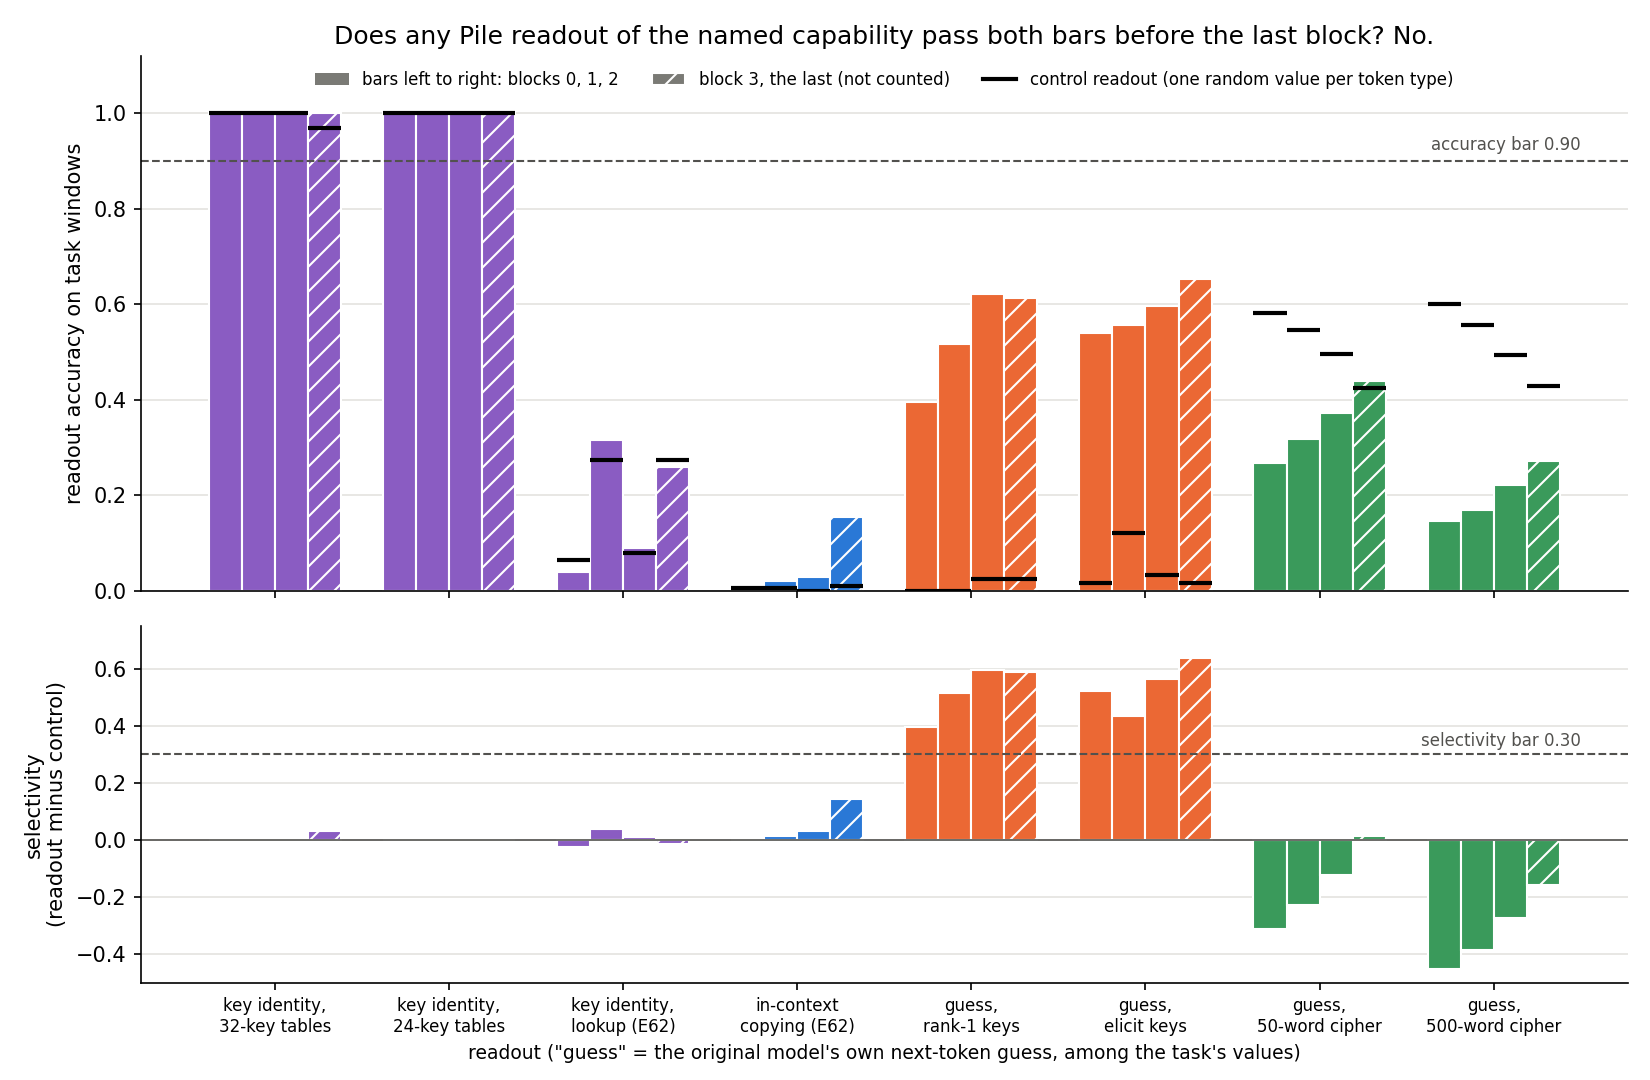

In [2]:
display(Image(FIG / "possession.png", width=950))


**Reading it.** No: not one readout clears both bars at a block before the last, so possession fails on every task. The top panel shows each readout's accuracy on the task windows, block by block, with its control readout as a black tick. The bottom panel shows the gap between them.

- **Key identity on the four key tables.** Both readouts are perfect at every block, so the gap is 0, as predicted. A relabelling of token types is learnt as well as the types themselves.
- **Key identity on the lookup's windows.** Both readouts sit far lower than on the key tables, at most a third, and their gap stays near 0. We did not predict the low accuracy, and its cause is untested.
- **In-context copying.** The readout of the copied word reads at most 0.03 before the last block, over 178 possible words; always guessing the commonest word scores 0.015. The control is near 0.
- **The original model's guess at the key tables.** These readouts clear the gap bar easily, but their accuracy peaks at 0.62 and 0.60 before the last block.
- **The original model's guess in the text ciphers.** The control readout beats the real one, so the gap is negative. A random value per word type is easier to read here than the model's own guess.

So the definition's first test fails for three different reasons: the capability is a token's type, it has too many values to read accurately, or a type relabelling reads better than the capability.


## Do the fine-tunes answer right on values they never trained on?


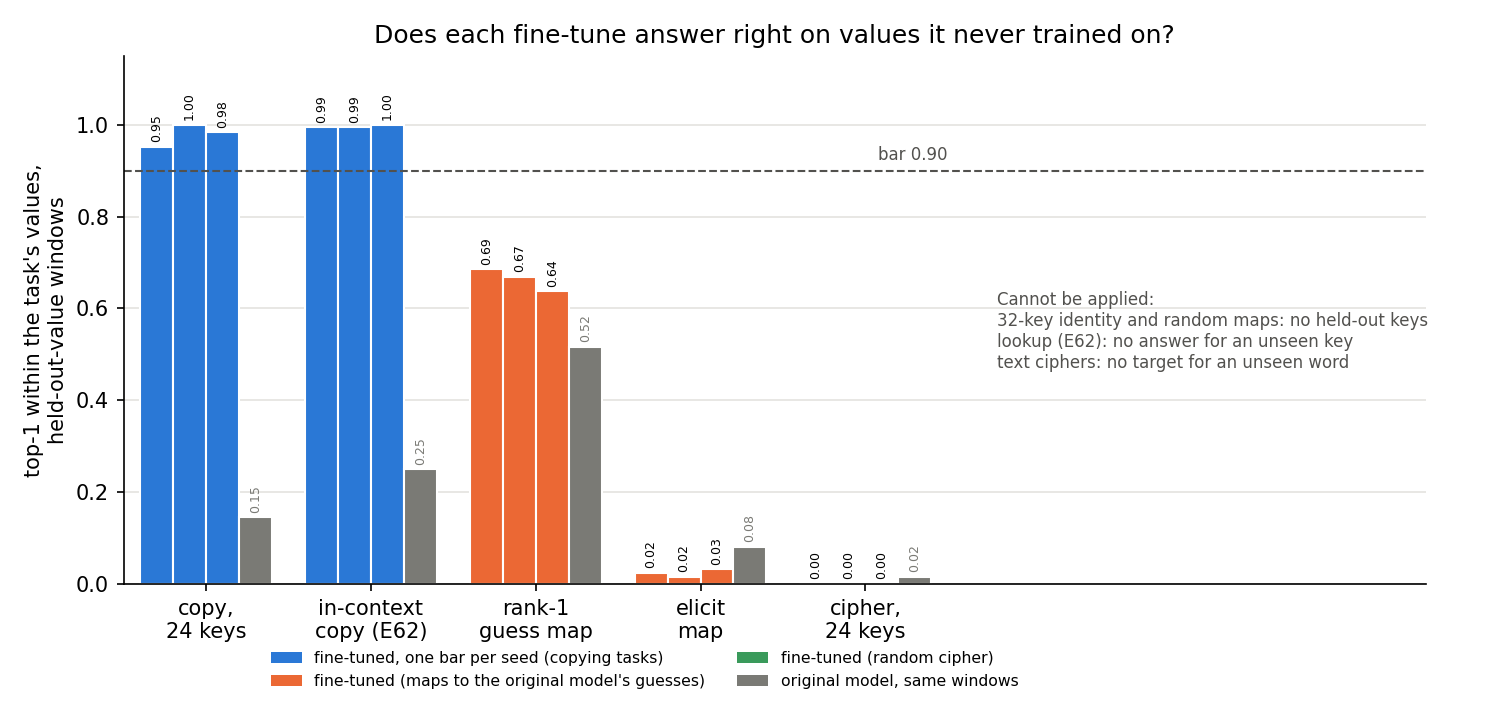

In [3]:
display(Image(FIG / "carrying.png", width=900))


**Reading it.** Only the two copying fine-tunes do. Each bar is one seed's top-1 accuracy among the task's values on windows whose value was never trained; the grey bar is the original model on the same windows. The 24-key copy map reads 0.95 to 1.0, against the original model's 0.15. In-context copying reads 0.995 to 1.0, against 0.25. Both were predicted.

The rank-1 guess map reads 0.64 to 0.69, under the bar. The original model reads only 0.52 on these windows, so "passes by construction" was wrong: its top guess at a key in these windows is often not the value the map assigns. The lower-guess map reads 0.02 to 0.03, below the original model. The 24-key cipher reads 0 on every seed. Both misses were predicted.

Carrying is one part of the definition. A pass here is not a reuse verdict, and a miss would give "not through C" only if possession had passed. Four tasks cannot be scored at all: the 32-key maps have no held-out keys, and the lookup and the text ciphers define no answer for a value they never saw.


## Does the definition agree with what we claimed earlier?

It cannot say, on any task. With possession failed, the small-function and removal parts were never read, so every row is "unreadable" or "does not apply". These rows are the finding, not a failure of the run: each says what shape a task must have before the frozen definition can read it. No rule is added to make a row readable. The full table, with carrying and the locator column, is in the report.

| Task | Earlier claim | Reading | What the definition needs to read it | Agrees? |
|---|---|---|---|---|
| identity map, 32 keys | reuse | unreadable | a capability not fixed by the key's token type; held-out keys | cannot say |
| copy map, 24 keys | reuse | unreadable | a capability not fixed by the key's token type | cannot say |
| in-context copying | reuses the copying heads | unreadable | a Pile readout of the copied word accurate before the last block | cannot say |
| lookup twin | new | unreadable | a capability not fixed by the token type; an answer for unseen keys | cannot say |
| random map, 32 keys | new | unreadable | as the identity map | cannot say |
| text ciphers, 50 and 500 words | new | unreadable | a readout that beats a per-type relabelled control; a target for unseen words | cannot say |
| cipher, 24 keys | new | unreadable | a capability not fixed by the key's token type | cannot say |
| lower-guess map | open | unreadable | a readout of the model's guess accurate before the last block | cannot say |
| rank-1 guess map | old | unreadable | as the lower-guess map | cannot say |
| lowercase, emoticon, one-pair map | reuse, existing, new | does not apply | an answer that depends on the input | cannot say |

Carrying alone leans one way on some rows, but it is one part and not a verdict. It sits with "reuse" on both copying maps, and with "new" on the 24-key cipher. On the rank-1 map it reads under the bar, against the earlier "old" label.


## What we learned

The adopted definition gives no label to any old 67M fine-tune. That is a reading of the frozen rule, not a failure of the run. It tells the Qwen anchors what shape a task must have to be read at all.

- **Possession needs a capability that varies with the input in a way a type relabelling cannot copy.** The readout must be scored on token types it never saw in training. The previous experiment's case readout was scored that way, on held-out word pairs, and passed. A capability that is just "which token is here", scored on the same tokens, cannot pass.
- **Possession also needs few values, or a far stronger readout.** The readouts of copying and of the model's guesses, over 18 to 500 values, stayed under 0.65 before the last block. The two-valued case readout reached 0.99.
- **Carrying is readable without any readout, wherever unseen values have a defined answer.** A lookup table or a cipher says nothing about a word it never saw, so there it cannot be read.

## What this means for step 2

Step 2 writes how the definition applies to the Qwen anchors. From this table, a task can be read only if three things hold. The named capability depends on the input, not on one token's identity. A Pile readout of it beats the per-type relabelled control on types the readout never trained on. The task defines an answer for values the fine-tune never trained on, so that carrying can be scored.

For the template against TOFU facts and the known against invented facts, step 2 must name such a capability for each arm, or report the arm unreadable. A recall capability with one value per fact runs into the many-valued problem seen here. A two-valued one, such as whether the subject is known, has the shape that passed in the case-label pair. No rule is added by saying so.

## How compelling is the evidence

The verdicts follow from the original model's readouts alone, so seeds do not enter them; carrying was read on two or three seeds per task, and the seeds agree to within 0.05. The readouts are ridge regressions at one position, as in the previous experiment; a stronger readout could pass where these fail, and that is not tested. The case-label readout reproduced exactly, so the moved code reads as before. The held-out sets are small: 124 windows over 8 keys on the 24-key tables, 200 windows on copying.

## Surprises

- **The in-context copying readout is near chance.** Copying is a known behaviour of this model, with located heads, but a Pile readout of the copied word reads at most 0.155, at the last block. The lead checked one candidate cause: on the Pile positions, the current token equals the label about one time in ten, and never on the task windows. That shortcut is small, so it does not explain the low accuracy. The cause is untested.
- **The rank-1 map does not pass carrying by construction.** The original model reads 0.52 on its held-out windows, against the 0.90 we expected. The fine-tunes read about two thirds.
- **Two readouts misbehaved against their filed expectations.** The key-identity readout on the lookup's windows reads at most a third, not near 1. The text ciphers' control readout beats the real one, at 0.42 to 0.60 against a chance level of one in fifty or less.

## What next

1. Step 2, the Qwen anchors: name each arm's capability and say whether it has the readable shape above. If none does, that is the finding, and the user decides the anchors.
2. If the user wants the copying row read at all, a readout scored on held-out copy contexts at the located heads' output would be a new readout, so a new plan, not an amendment.


## Scorecard

| id | Claim in words | Rule | Read | Verdict |
|---|---|---|---|---|
| stage 0 | the moved code reproduces E112's readout | every block within 0.001 | max difference 0.0 | held |
| W0 type-level | key identity and its control both near 1 | selectivity near 0, P0 fails | 1.0 and 1.0 on the four key tables; lookup 0.04-0.32 and 0.07-0.28 | held on four; missed on lookup, P0 fails either way |
| W0 copy, guess | under 0.90 at blocks 0-2, control near 1/m | as stated | copy at most 0.03, guesses at most 0.62; controls 0-0.12, text ciphers 0.42-0.60 | held; text ciphers' control missed |
| W0 P1 | near its prior; rank-1 passes by construction | P1 >= 0.90 on rank-1 | rank-1 0.52 | missed on rank-1 |
| ident32, rand32 | unreadable | P0 fails, P1 n/a | selectivity 0.0 | held |
| copy24 | unreadable; P1 no lean | P0 fails | selectivity 0.0; P1 0.95-1.0 | held |
| e62_copy | unreadable; P1 >= 0.90 | P0 lean fails | accuracy at most 0.03 before block 3; P1 0.995-1.0 | held |
| e62_lookup | unreadable; P1 n/a | P0 fails | selectivity -0.03 to 0.04 | held |
| cipher, broad_cipher | unreadable; P1 n/a | P0 lean fails | selectivity -0.45 to -0.12 before block 3 | held |
| cipher24 | unreadable; P1 under 0.90 | P0 fails | selectivity 0.0; P1 0.0 | held |
| elicit | unreadable, else not through C; P1 under 0.90 | P0 lean fails | accuracy at most 0.60 before block 3; P1 0.02-0.03 | held, "unreadable" |
| rank1 | unreadable, else not through C; P1 >= 0.90 | P0 lean fails | accuracy at most 0.62; P1 0.64-0.69 | P0 held; P1 missed |
| lowercase, rand1, emoticon | does not apply | constant answer | not loaded | held |
| do-nothing direction, P2, P3, twins | read under a C with a site | as filed | not read: no C has a site | no reading |


## Departures from the literature

- Jain and colleagues train the readout on their synthetic pretraining data; here it is a ridge regression per value on Pile residuals at one position, as in the previous experiment.
- Jain's possession holds "for all inputs"; here it is the bars of 0.90 accuracy and 0.30 selectivity, filed for the previous experiment.
- Jain put no bound on the small function; held-out carrying is the user's dated departure, row 87.
- Direction removal is our addition, from row 81; Jain's causal evidence is pruning and reverse fine-tuning. Neither ran here, as no capability had a site.
- The "pruning a few neurons" column is the locator's part-level revert, copied from earlier results, not Jain's pruning algorithm.
- The control gives one random value per token type, as Hewitt and Liang's control tasks do per word type; their probes are classifiers, ours are ridge regressions.
- For a capability with more than two values the small function was filed as the identity on classes or a fitted table; it was never read.

## Not run

- The small-function test, the removal test, the random-direction control and every twin's removal share: no capability had a block where possession passed.
- Any readout other than a one-position ridge regression; a readout at the located heads' output.
- Pruning, reverse fine-tuning and patching on these states.
- Any fine-tune, new task or new windows; the 32-key elicit and cipher states; seeds 3 to 7 of the 24-key maps.
- A held-out target for the text ciphers or the lookup: none is defined, and none was added.

## Provenance

Job 54440 on the MATS cluster's `debug` L40, about 20 minutes, $0, exit 0. Results in `experiments/definition_table/results/stage0.json`, `stage1.json`, `stage2.json` and `run.out`, with the input files' sha256 at the end of the log. Filed predictions `experiments/definition_table/results/predictions.json`. Plan `reports/plans/2026-11-06_plan_e116-definition-table.md`; report `reports/analyses/2026-11-06_analysis_e116-definition-table.md`. The lead's copy-readout check is in `~/commute-data/scratch/definition-lead/e116-copycheck/check.json`.
